In [1]:
import pandas as pd 

tweets = pd.read_csv('tweets.csv', encoding="utf-8")

tweets.head()

,tweet,topic
0,@sssdddnnn333 @MohammedAlDeaye حارس حتى عنده ض...,Sports
1,RT @fahadaljehani: الكثير من المتعة كانت حاضره...,Sports
2,RT @aboaljorya: @AhmedAllshehri عذيب 👀\nالسعر ...,Business
3,RT @salem_d29: الحمدلله ، شعوري لا يوصف ، ولن ...,Sports
4,أبل أبدعت بهذي الميزة الأمر مستحيل ومجرد خيال ...,Technology


In [2]:
print('data size :', tweets.shape)

data size : (26747, 2)


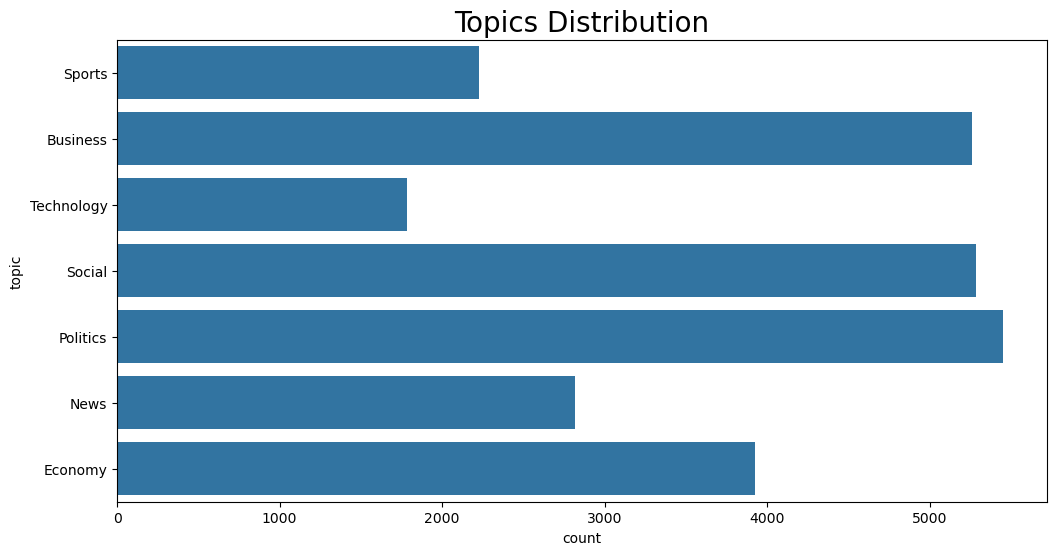

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

sns.countplot(data=tweets, y='topic')

plt.title('Topics Distribution', fontsize=20)

plt.show()

In [9]:
!pip install nltk

In [11]:
import string
import re
import nltk

nltk.download('punkt')
nltk.download('stopwords')

# Corrected 'ntlk' to 'nltk'
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from snowballstemmer import stemmer

def remove_chars(text, del_chars):
    for char in del_chars:
        text = text.replace(char, "")
    return text

def remove_repeating_char(text):
    return re.sub(r'(.)\1{2,}', r'\1', text)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [15]:
import string
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from snowballstemmer import stemmer

# --- Helper Functions ---

def remove_chars(text, del_chars):
    for char in del_chars:
        text = text.replace(char, "")
    return text

def remove_repeating_char(text):
    return re.sub(r'(.)\1{2,}', r'\1', text)

# Define clean_tweet before calling it in process_tweet
def clean_tweet(tweet):
    # Removes URLs, user mentions (@username), numbers, punctuation, and extra whitespace
    tweet = re.sub(r'http\S+|www\S+|https\S+', '', tweet, flags=re.MULTILINE)
    tweet = re.sub(r'@\w+', '', tweet)
    tweet = re.sub(r'\d+', '', tweet)
    tweet = remove_repeating_char(tweet)
    tweet = remove_chars(tweet, string.punctuation + '🌝،!')
    return tweet.strip()

def tokenizingText(text):
    return word_tokenize(text)

def filteringText(tokens):
    arabic_stopwords = set(stopwords.words('arabic'))
    return [w for w in tokens if w not in arabic_stopwords]

def stemmingText(tokens):
    ar_stemmer = stemmer('arabic')
    return [ar_stemmer.stemWord(w) for w in tokens]

# --- Main Pipeline ---

def process_tweet(tweet):
    tweet = clean_tweet(tweet)
    tokens_list = tokenizingText(tweet)
    tokens_list = filteringText(tokens_list)
    tokens_list = stemmingText(tokens_list)
    return tokens_list

# --- Execution ---

text = "أنا أحب الذهاب إلى الحديقة 🌝، كل يوم 9 صباحاً، مع رفاقي هؤلاء! @toto  "
processed_tweet = process_tweet(text)
print(processed_tweet)

['احب', 'ذهاب', 'حديق', 'يوم', 'صباح', 'رفاق']


In [16]:
def tokenizingText(text):
    tokens_list = word_tokenize(text)
    return tokens_list

def filteringText(tokens_list):
    
    listStopwords = stopwords.words('arabic')
    filtered = []
    for txt in tokens_list:
        if txt not in listStopwords:
            filtered.append(txt)
    return filtered

def stemmingText(tokens_list): 
    
    ar_stemmer = stemmer("arabic")
    tokens_list = [ar_stemmer.stemWord(word) for word in tokens_list]
    return tokens_list
    
def toSentence(words_list):  
    sentence = ' '.join(word for word in words_list)
    return sentence

In [17]:
def process_tweet(tweet):
    
    tweet=clean_tweet(tweet)
    
    tokens_list=tokenizingText(tweet)
    
    tokens_list=filteringText(tokens_list)
    
    tokens_list=stemmingText(tokens_list)
    return tokens_list

In [18]:
text= "أنا أحب الذهاب إلى الحديقة 🌝، كل يوم 9 صباحاً، مع رفاقي هؤلاء! @toto  "

processed_tweet= process_tweet(text)
print(processed_tweet)

['احب', 'ذهاب', 'حديق', 'يوم', 'صباح', 'رفاق']


In [19]:
tweets['tweet'] = tweets['tweet'].apply(process_tweet)

tweets

,tweet,topic
0,"[حارس, عند, ضعف, نظر, مدر, يحرص, عموم, حال, حا...",Sports
1,"[RT, كثير, متع, كان, حاضر, ملعب, قيم, الفن, عا...",Sports
2,"[RT, عذيب, 👀, سعر, حال]",Business
3,"[RT, حمدلله, شعور, يوصف, ولن, انسي, فضل, جمهور...",Sports
4,"[ابل, ابدع, بهذ, ميز, امر, مستحيل, مجرد, خيال,...",Technology
...,...,...
26742,"[خير, سحب, مبلغ, الاف, ولم, تخرج, صراف, طريق, ...",Business
26743,"[صرف, ادو, ياخذ, اسبوع, لاسبوع, والادو, باق, ا...",Business
26744,"[جيت, قدم, لاغ, يوم, رقع, اسعار, تطبيق, مشكل, ...",Business
26745,"[حال, توف, مريض, مستشفي, حق, مطالب, ماليه, نرج...",Business


In [20]:
from imblearn.over_sampling import RandomOverSampler

oversample = RandomOverSampler()

tweets, Y = oversample.fit_resample(tweets, tweets.topic)

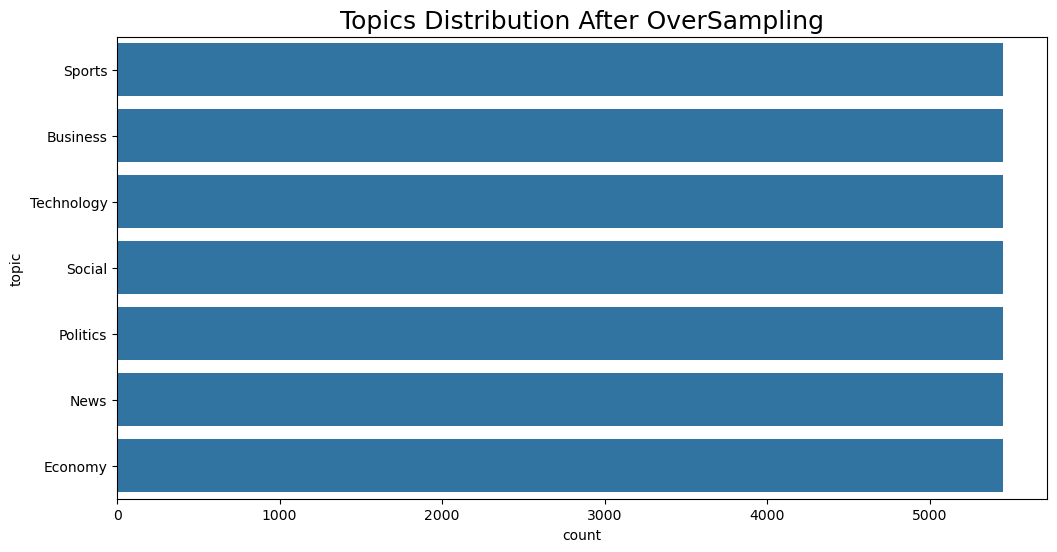

In [21]:
plt.figure(figsize=(12, 6))

sns.countplot(data=tweets, y='topic');
plt.title('Topics Distribution After OverSampling', fontsize=18)

plt.show()

In [22]:
from sklearn.preprocessing import LabelEncoder

le_topics = LabelEncoder()
tweets['topic'] = tweets[['topic']].apply(le_topics.fit_transform)

classes = le_topics.classes_

n_classes = len(classes)
print("No. of classes:", n_classes)
print("Classes:", classes)
print("Coding: ", le_topics.transform(classes))

No. of classes: 7
Classes: ['Business' 'Economy' 'News' 'Politics' 'Social' 'Sports' 'Technology']
Coding:  [0 1 2 3 4 5 6]


In [23]:
sentences = tweets['tweet'].apply(toSentence)

sentences

0        حارس عند ضعف نظر مدر يحرص عموم حال حال لاعب هل...
1        RT كثير متع كان حاضر ملعب قيم الفن عاليه سالما...
2                                        RT عذيب 👀 سعر حال
3        RT حمدلله شعور يوصف ولن انسي فضل جمهور هلال عل...
4        ابل ابدع بهذ ميز امر مستحيل مجرد خيال سنة ايبا...
                               ...                        
38145    تعديل مهم قادم تويتر صفح تصفح تغريد يكون خيار ...
38146    ان اغلب حب شكل جديد لصفح تغريد تويتر شرح تفعل ...
38147                                        عاد اخذ صوره؟
38148    فايروس خطير جدا استهدف مستخدم نظام اندرويد قاد...
38149    فايروس خطير جدا استهدف مستخدم نظام اندرويد قاد...
Name: tweet, Length: 38150, dtype: object

In [27]:
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer()

tokenizer.fit_on_texts(sentences)
num_words = len(tokenizer.word_counts)
print("Number of words:", num_words)

Number of words: 24082


In [28]:
max_words = 10000

tokenizer = Tokenizer(num_words=max_words )

tokenizer.fit_on_texts(sentences)

X = tokenizer.texts_to_sequences(sentences)

In [29]:
print(X[0])
print(X[1])

[3077, 48, 1654, 233, 1473, 5557, 2516, 171, 171, 686, 2, 3918, 4200, 6378]
[4979, 302, 1962, 250, 3254, 3255, 186, 304, 6379, 6380, 530, 1805, 4980, 2012]


In [30]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_len = 50

X = pad_sequences(X, maxlen=max_len)
print(X[0])
print(X[1])

[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0 3077   48 1654  233 1473 5557
 2516  171  171  686    2 3918 4200 6378]
[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0 4979  302 1962  250 3254 3255
  186  304 6379 6380  530 1805 4980 2012]


In [31]:
tweets

,tweet,topic
0,"[حارس, عند, ضعف, نظر, مدر, يحرص, عموم, حال, حا...",5
1,"[RT, كثير, متع, كان, حاضر, ملعب, قيم, الفن, عا...",5
2,"[RT, عذيب, 👀, سعر, حال]",0
3,"[RT, حمدلله, شعور, يوصف, ولن, انسي, فضل, جمهور...",5
4,"[ابل, ابدع, بهذ, ميز, امر, مستحيل, مجرد, خيال,...",6
...,...,...
38145,"[تعديل, مهم, قادم, تويتر, صفح, تصفح, تغريد, يك...",6
38146,"[ان, اغلب, حب, شكل, جديد, لصفح, تغريد, تويتر, ...",6
38147,"[عاد, اخذ, صوره؟]",6
38148,"[فايروس, خطير, جدا, استهدف, مستخدم, نظام, اندر...",6


In [32]:
y=tweets['topic']
y

0        5
1        5
2        0
3        5
4        6
        ..
38145    6
38146    6
38147    6
38148    6
38149    6
Name: topic, Length: 38150, dtype: int64

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 0)

In [34]:
from keras.models import Sequential

from keras.layers import Embedding, Dense, LSTM

embed_dim = 32
hidden_unit = 16
dropout_rate = 0.2

model = Sequential()

model.add(Embedding(input_dim = max_words, output_dim = embed_dim, input_length = max_len))

model.add(LSTM(units = hidden_unit, dropout=dropout_rate))

model.add(Dense(units = len(classes), activation = 'softmax'))

C:\ProgramData\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:103: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [35]:
model.compile(loss = 'sparse_categorical_crossentropy', 
              optimizer = 'adam', metrics = ['accuracy'])

In [36]:
history = model.fit(X_train, y_train,
                             epochs=10, batch_size=32,
                             validation_data=(X_test, y_test))

Epoch 1/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 32s 28ms/step - accuracy: 0.7417 - loss: 0.8245 - val_accuracy: 0.8757 - val_loss: 0.4228
Epoch 2/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9180 - loss: 0.2871 - val_accuracy: 0.9077 - val_loss: 0.3165
Epoch 3/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9499 - loss: 0.1737 - val_accuracy: 0.9127 - val_loss: 0.3020
Epoch 4/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.9661 - loss: 0.1185 - val_accuracy: 0.9175 - val_loss: 0.3052
Epoch 5/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9758 - loss: 0.0870 - val_accuracy: 0.9189 - val_loss: 0.3281
Epoch 6/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.9796 - loss: 0.0705 - val_accuracy: 0.9186 - val_loss: 0.3350
Epoch 7/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.9830 - loss: 0.0574 - val_accuracy: 0.9172 - val_loss: 0.3517
Epoch 8/10
895/895 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.9857 - loss: 0.0494 - 

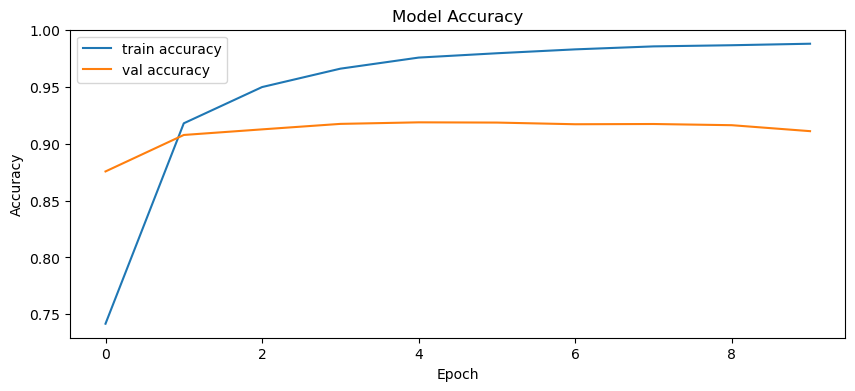

In [37]:
fig, ax = plt.subplots(figsize = (10, 4))

ax.plot(history.history['accuracy'], label = 'train accuracy')
ax.plot(history.history['val_accuracy'], label = 'val accuracy')

ax.set_title('Model Accuracy')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.legend(loc = 'upper left')

plt.show()

In [38]:
model.save('perosn_classification_model.keras')

import pickle
tokenizer_path = 'perosn_classification_tokenizer'
with open(tokenizer_path, 'wb') as file:
    pickle.dump(tokenizer, file)

In [39]:
import numpy as np

def classify_tweet(tweet, model, tokenizer, max_len=50):
    
    seq = tokenizer.texts_to_sequences([tweet])
    
    pseq = pad_sequences(seq, maxlen=max_len)
    
    predections = model.predict(pseq)
    
    pred=np.argmax(predections)
    return pred

In [40]:
from keras.models import load_model
import pickle
classes= ['Business', 'Economy', 'News', 'Politics', 'Social', 'Sports', 'Technology']

def classify_person(person_name,model_path, tokenizer_path, person_path):
    
    model = load_model(model_path)
    
    with open(tokenizer_path, 'rb') as file:
        tokenizer = pickle.load(file)
    
    df = pd.read_csv(person_path)
    
    classes_count=dict()
    
    for i in range(len(classes)):
        key=classes[i]
        classes_count[key]=0

    for _, row in df.iterrows():
        tweet=row['tweet']
        
        processed_tweet=process_tweet(tweet)
        
        code= classify_tweet(processed_tweet, model, tokenizer)
        
        topic=classes[code]
        
        classes_count[topic]=classes_count[topic]+1
 

    x = classes_count.keys()
    y = classes_count.values()

    import matplotlib.pyplot as plt
    # pie
    plt.figure(figsize=(5,5))
    plt.title(person_name, fontdict = {'fontsize':20})
    plt.pie(y, labels = x,autopct='%1.1f%%')
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━

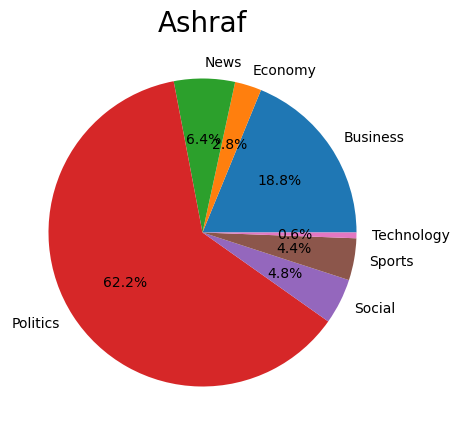

In [41]:
classify_person("Ashraf", 'perosn_classification_model.keras',
                'perosn_classification_tokenizer','ashraf.csv')